# Setup

In [1]:
import sys
from pathlib import Path
from data import prepare
from config import load_config

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

print("PROJECT_ROOT =", PROJECT_ROOT)


sys.path.insert(0, str(PROJECT_ROOT / "src"))


cfg = load_config(PROJECT_ROOT / "configs/config.yaml")

cfg["data"]["root"] = str(
    PROJECT_ROOT.parent.parent / "PTB-XL"
)

print(cfg["data"])

cache, manifest = prepare(cfg)

print("Cache:", cache)
print(manifest["splits"])

FIG_DIR = Path("figures")

(FIG_DIR / "patchtst").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "tft").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "comparison").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "leads").mkdir(parents=True, exist_ok=True)


ImportError: cannot import name 'prepare' from 'data' (unknown location)

# PatchTST Patch Length Comparison (MAE)

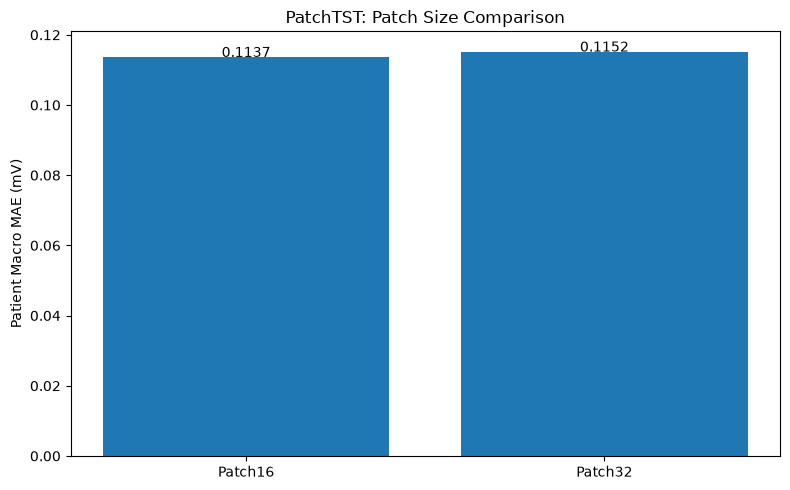

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

p16 = pd.read_csv(
    "../results/primary_7s3s_v3/full/checkpoints/"
    "patchtst_P0_F0_full_120e/history.csv"
)

p32 = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/"
    "patchtst32_P0_F0_full_60e/history.csv"
)

best16 = p16.loc[
    p16["val_patient_macro_mae_mV"].idxmin()
]

best32 = p32.loc[
    p32["val_patient_macro_mae_mV"].idxmin()
]

comparison = pd.DataFrame({
    "Model": [
        "Patch16",
        "Patch32",
    ],
    "MAE": [
        best16["val_patient_macro_mae_mV"],
        best32["val_patient_macro_mae_mV"],
    ],
})

plt.figure(figsize=(8,5))

bars = plt.bar(
    comparison["Model"],
    comparison["MAE"]
)

plt.ylabel("Patient Macro MAE (mV)")
plt.title("PatchTST: Patch Size Comparison")

for b in bars:
    plt.text(
        b.get_x() + b.get_width()/2,
        b.get_height(),
        f"{b.get_height():.4f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" / "patchtst_patchsize_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Patch16 vs Patch32 Learning Curves

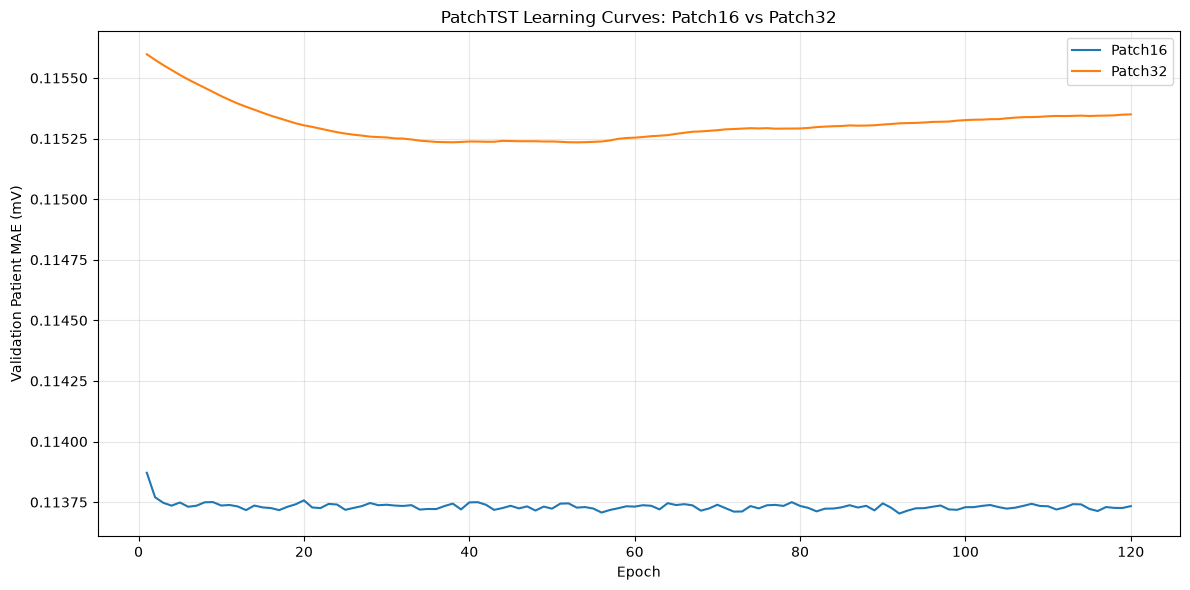

In [5]:
plt.figure(figsize=(12,6))

plt.plot(
    p16["epoch"],
    p16["val_patient_macro_mae_mV"],
    label="Patch16"
)

plt.plot(
    p32["epoch"],
    p32["val_patient_macro_mae_mV"],
    label="Patch32"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Patient MAE (mV)")
plt.title(
    "PatchTST Learning Curves: Patch16 vs Patch32"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "patchtst_patchsize_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




# TFT Medium vs Large Learning Curves 

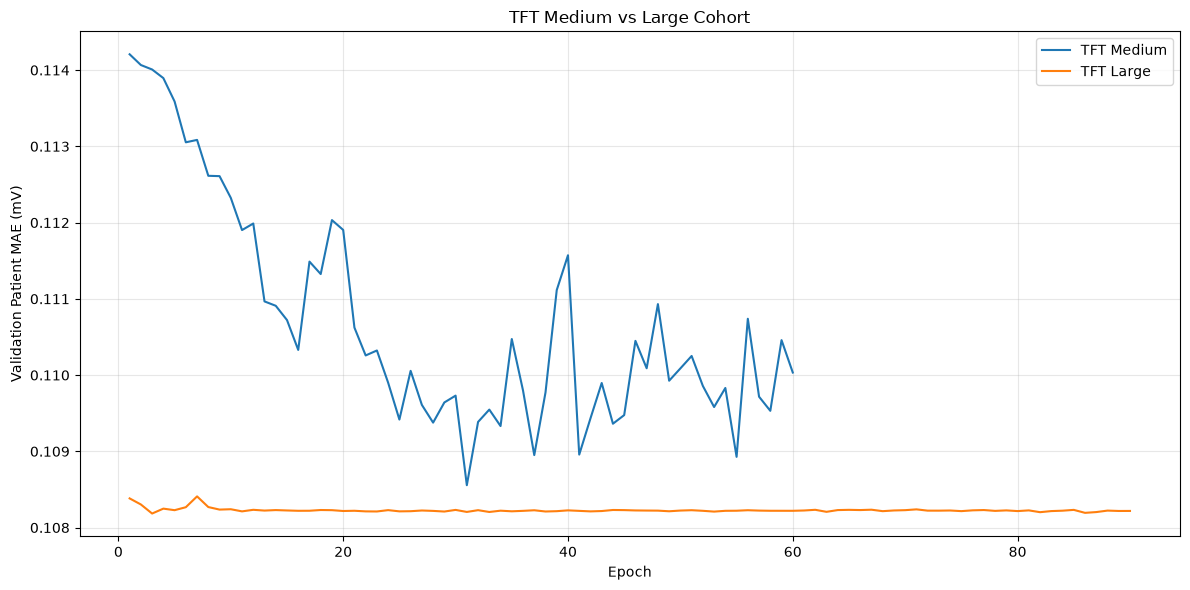

In [6]:
tft_medium = pd.read_csv(
    "../results/primary_7s3s_v3/medium/checkpoints/"
    "tft_P0_F0_medium_60e/history.csv"
)

tft_large = pd.read_csv(
    "results/primary_7s3s_v3/large/checkpoints/"
    "tft_P0_F0_large_80e/history.csv"
)

plt.figure(figsize=(12,6))

plt.plot(
    tft_medium["epoch"],
    tft_medium["val_patient_macro_mae_mV"],
    label="TFT Medium"
)

plt.plot(
    tft_large["epoch"],
    tft_large["val_patient_macro_mae_mV"],
    label="TFT Large"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Patient MAE (mV)")

plt.title(
    "TFT Medium vs Large Cohort"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "tft_medium_vs_large_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# TFT Large P0 vs P1 Learning Curves 

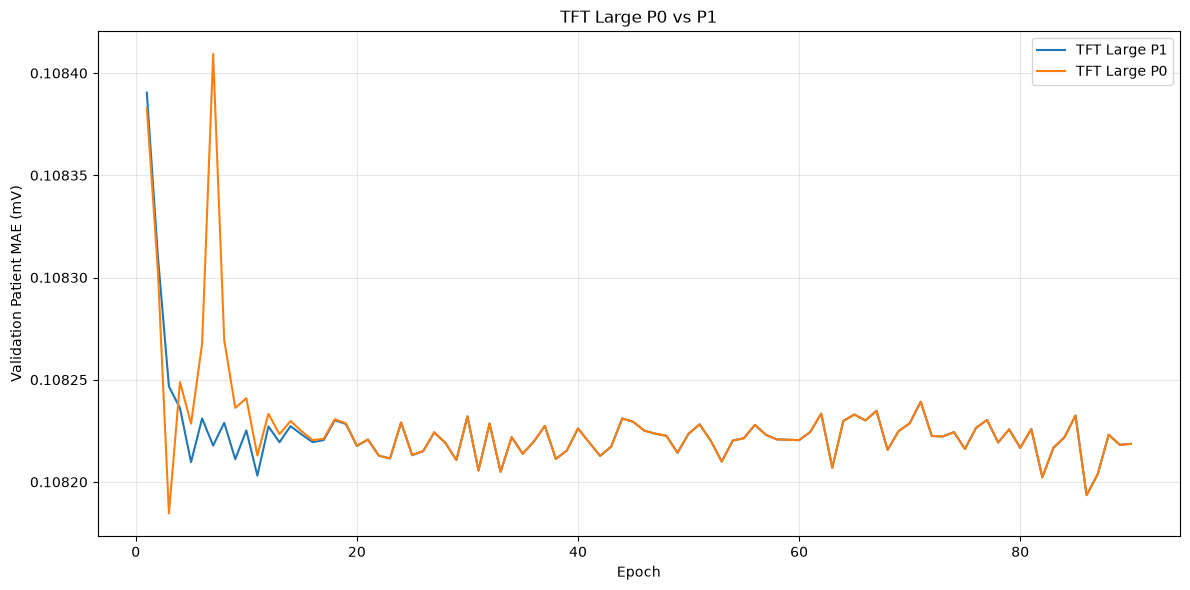

In [68]:
tft_large_p1 = pd.read_csv(
    "results/primary_7s3s_v3/large/checkpoints/"
    "tft_P1_F0_large_80e/history.csv"
)

tft_large_p0 = pd.read_csv(
    "results/primary_7s3s_v3/large/checkpoints/"
    "tft_P0_F0_large_80e/history.csv"
)

plt.figure(figsize=(12,6))

plt.plot(
    tft_large_p1["epoch"],
    tft_large_p1["val_patient_macro_mae_mV"],
    label="TFT Large P1"
)

plt.plot(
    tft_large_p0["epoch"],
    tft_large_p0["val_patient_macro_mae_mV"],
    label="TFT Large P0"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Patient MAE (mV)")

plt.title(
    "TFT Large P0 vs P1"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "tft_large_p0_vs_p1_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# TFT Medium vs Large MAE

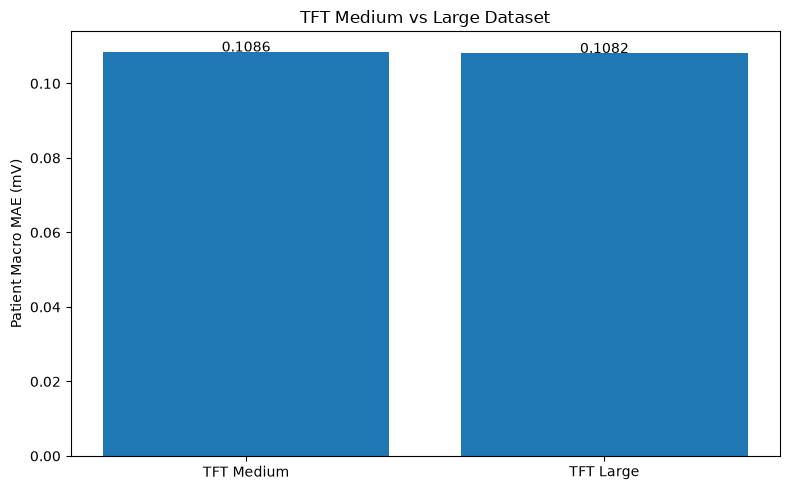

In [8]:
best_medium = tft_medium.loc[
    tft_medium["val_patient_macro_mae_mV"].idxmin()
]

best_large = tft_large.loc[
    tft_large["val_patient_macro_mae_mV"].idxmin()
]

comparison = pd.DataFrame({
    "Run": [
        "TFT Medium",
        "TFT Large"
    ],
    "MAE": [
        best_medium["val_patient_macro_mae_mV"],
        best_large["val_patient_macro_mae_mV"]
    ]
})

plt.figure(figsize=(8,5))

bars = plt.bar(
    comparison["Run"],
    comparison["MAE"]
)

for b in bars:
    plt.text(
        b.get_x()+b.get_width()/2,
        b.get_height(),
        f"{b.get_height():.4f}",
        ha="center"
    )

plt.ylabel("Patient Macro MAE (mV)")
plt.title("TFT Medium vs Large Dataset")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "tft_medium_vs_large_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
print(best16["val_patient_macro_mae_mV"])
print(best32["val_patient_macro_mae_mV"])


print(best_medium["val_patient_macro_mae_mV"])
print(best_large["val_patient_macro_mae_mV"])


0.113702951232371
0.1152344599366188
0.1085561602102407
0.1081845357796798


# Transformer Performance Evolution

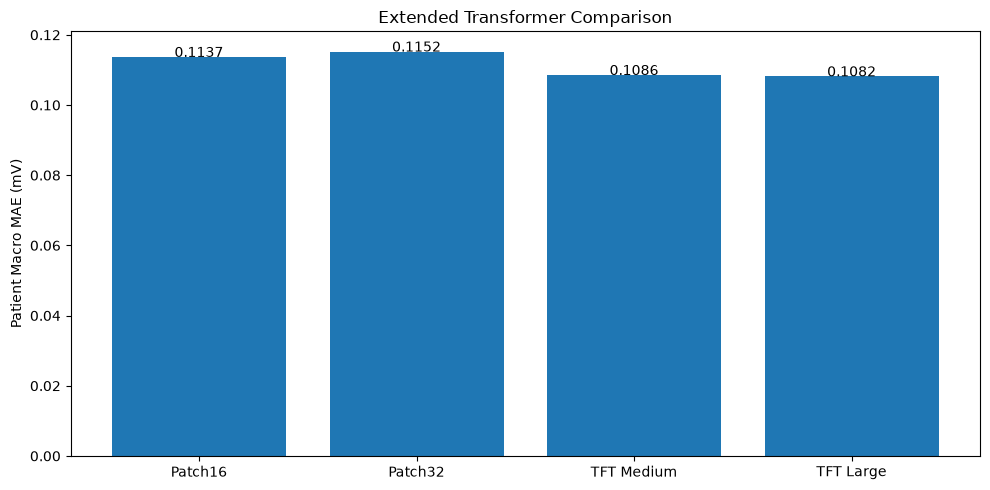

In [17]:
import matplotlib.pyplot as plt

models = [
    "Patch16",
    "Patch32",
    "TFT Medium",
    "TFT Large"
]

mae = [
    0.113702951232371,
    0.1152344599366188,
    0.1085561602102407,
    0.1081845357796798,
]

plt.figure(figsize=(10,5))

bars = plt.bar(
    models,
    mae
)

plt.ylabel("Patient Macro MAE (mV)")

plt.title(
    "Extended Transformer Comparison"
)

for b in bars:
    plt.text(
        b.get_x()+b.get_width()/2,
        b.get_height(),
        f"{b.get_height():.4f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "extended_transformer_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# RMSE Comparison Across Cohort Sizes

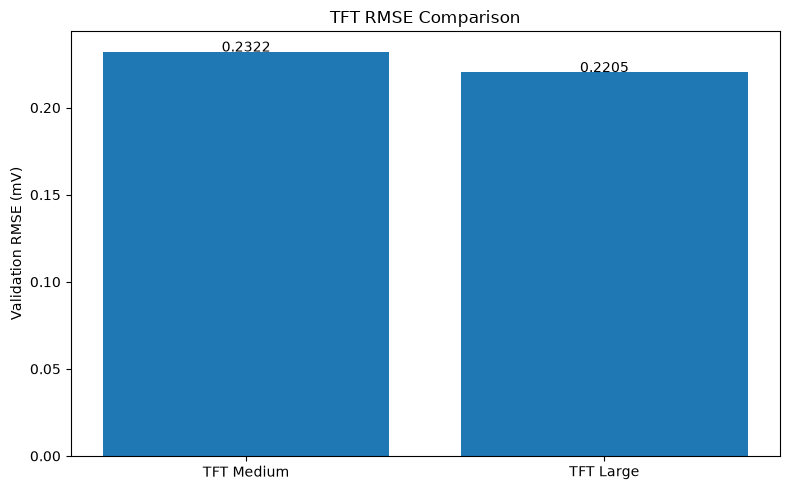

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

tft_medium = pd.read_csv(
    "../results/primary_7s3s_v3/medium/checkpoints/"
    "tft_P0_F0_medium_60e/history.csv"
)

tft_large = pd.read_csv(
    "results/primary_7s3s_v3/large/checkpoints/"
    "tft_P0_F0_large_80e/history.csv"
)

best_medium = tft_medium.loc[
    tft_medium["val_patient_macro_mae_mV"].idxmin()
]

best_large = tft_large.loc[
    tft_large["val_patient_macro_mae_mV"].idxmin()
]

plt.figure(figsize=(8,5))

bars = plt.bar(
    ["TFT Medium", "TFT Large"],
    [
        best_medium["val_rmse_mV"],
        best_large["val_rmse_mV"],
    ]
)

plt.ylabel("Validation RMSE (mV)")
plt.title("TFT RMSE Comparison")

for b in bars:
    plt.text(
        b.get_x()+b.get_width()/2,
        b.get_height(),
        f"{b.get_height():.4f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "tft_rmse_medium_vs_large.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Train vs Validation MAE Curves

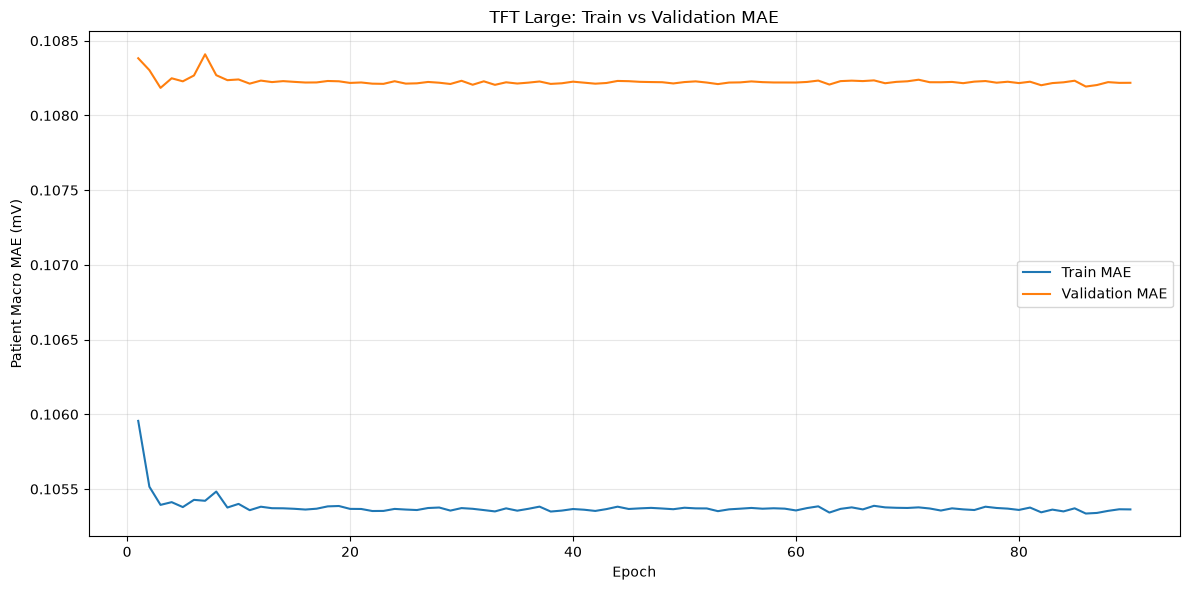

In [19]:
plt.figure(figsize=(12,6))

plt.plot(
    tft_large["epoch"],
    tft_large["train_patient_macro_mae_mV"],
    label="Train MAE"
)

plt.plot(
    tft_large["epoch"],
    tft_large["val_patient_macro_mae_mV"],
    label="Validation MAE"
)

plt.xlabel("Epoch")
plt.ylabel("Patient Macro MAE (mV)")

plt.title(
    "TFT Large: Train vs Validation MAE"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "tft" /
    "tft_large_train_vs_validation_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Train vs Validation RMSE

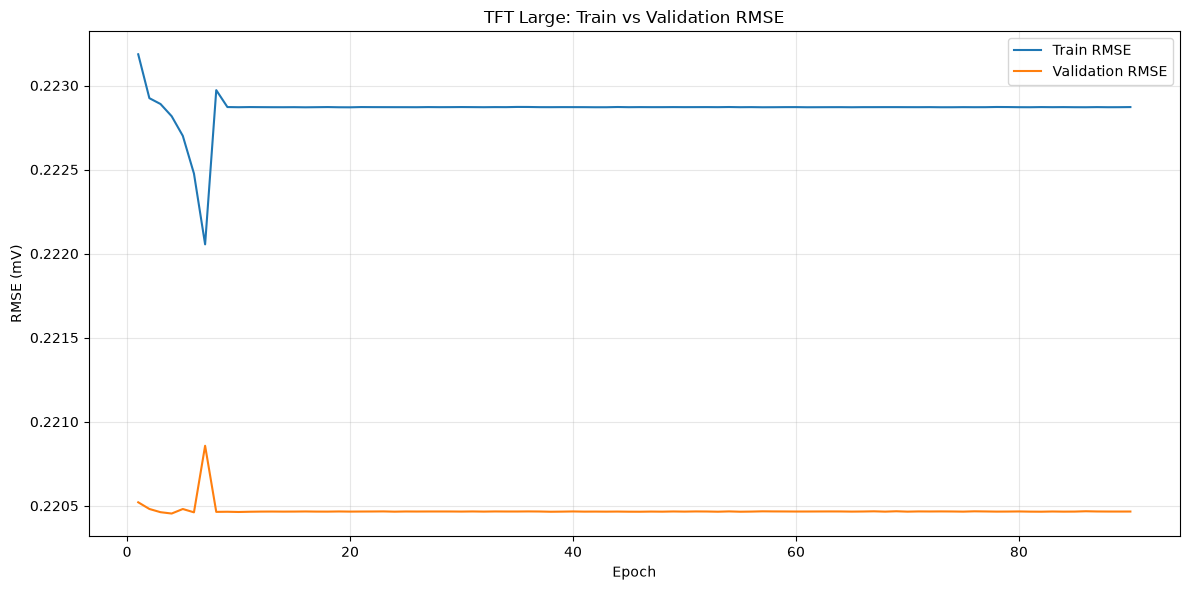

In [20]:
plt.figure(figsize=(12,6))

plt.plot(
    tft_large["epoch"],
    tft_large["train_rmse_mV"],
    label="Train RMSE"
)

plt.plot(
    tft_large["epoch"],
    tft_large["val_rmse_mV"],
    label="Validation RMSE"
)

plt.xlabel("Epoch")
plt.ylabel("RMSE (mV)")

plt.title(
    "TFT Large: Train vs Validation RMSE"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "tft" /
    "tft_large_train_vs_validation_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# TFT Medium vs Large MAE Comparison

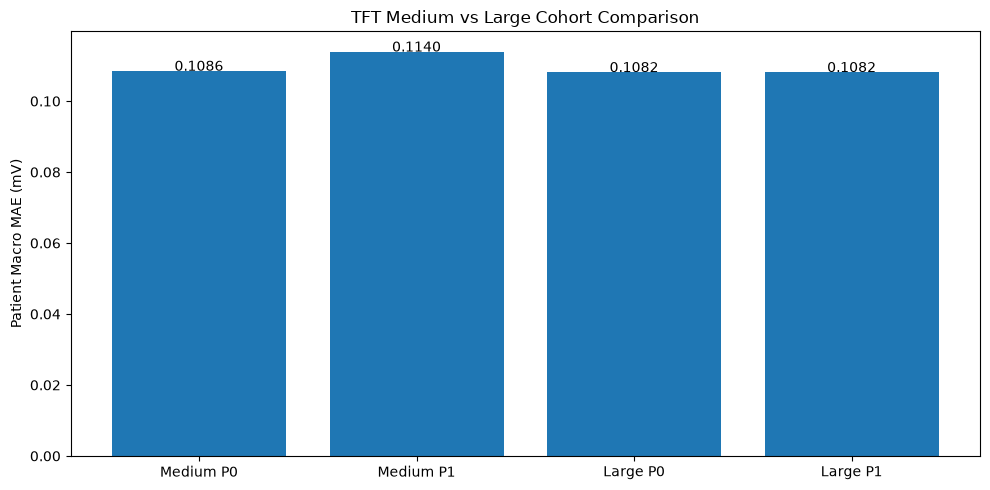

In [40]:
import matplotlib.pyplot as plt
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Medium P0",
        "Medium P1",
        "Large P0",
        "Large P1",
    ],
    "MAE": [
        0.1085561602102407,
        0.113963,          # replace with exact value if different
        0.1081845357796798,
        0.108194,
    ]
})

plt.figure(figsize=(10,5))

bars = plt.bar(
    comparison["Model"],
    comparison["MAE"]
)

for b in bars:
    plt.text(
        b.get_x()+b.get_width()/2,
        b.get_height(),
        f"{b.get_height():.4f}",
        ha="center"
    )

plt.ylabel("Patient Macro MAE (mV)")
plt.title("TFT Medium vs Large Cohort Comparison")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "tft_medium_large_p0_p1_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# TFT Medium vs Large RMSE

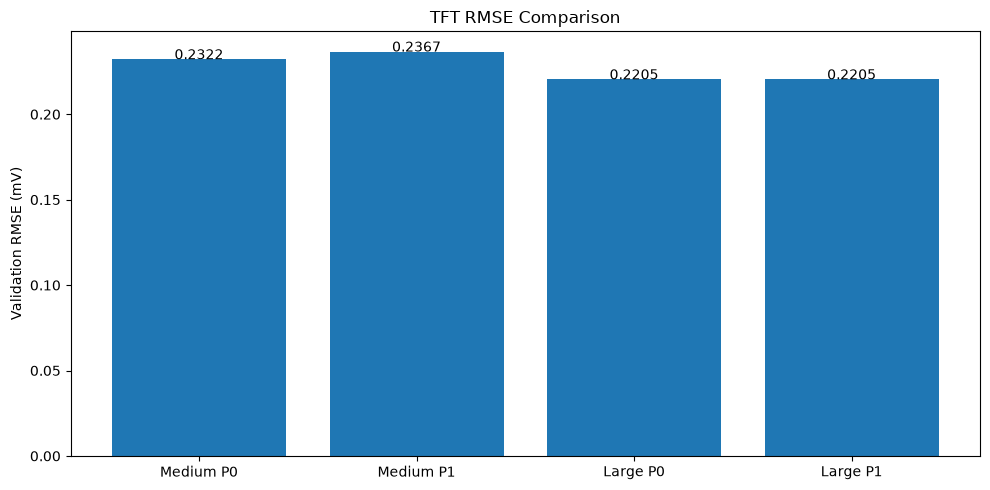

In [41]:
comparison = pd.DataFrame({
    "Model": [
        "Medium P0",
        "Medium P1",
        "Large P0",
        "Large P1"
    ],
    "RMSE": [
        0.232228,
        0.236698,      # replace with exact medium P1 value if needed
        0.220462,
        0.220468,
    ]
})

plt.figure(figsize=(10,5))

bars = plt.bar(
    comparison["Model"],
    comparison["RMSE"]
)

for b in bars:
    plt.text(
        b.get_x()+b.get_width()/2,
        b.get_height(),
        f"{b.get_height():.4f}",
        ha="center"
    )

plt.ylabel("Validation RMSE (mV)")
plt.title("TFT RMSE Comparison")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "tft_medium_large_p0_p1_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# PatchTST Hyperparameter Comparison

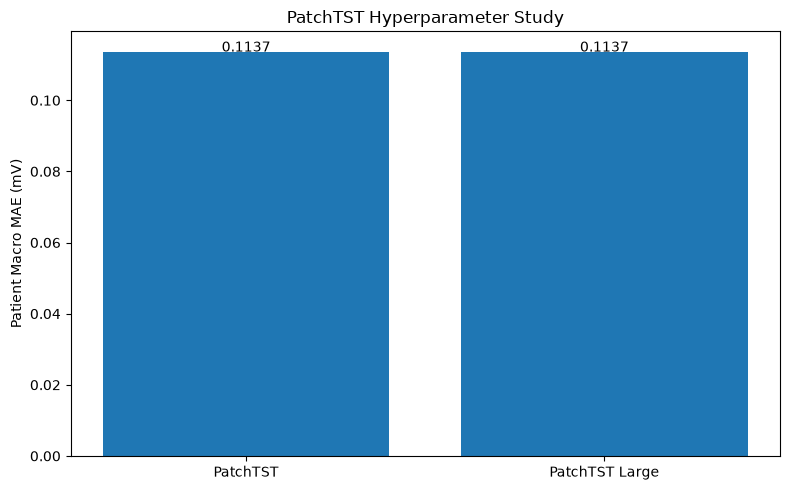

In [42]:
comparison = pd.DataFrame({
    "Model": [
        "PatchTST",
        "PatchTST Large"
    ],
    "MAE": [
        0.113702951232371,
        0.113702951232371,
    ]
})

plt.figure(figsize=(8,5))

bars = plt.bar(
    comparison["Model"],
    comparison["MAE"]
)

for b in bars:
    plt.text(
        b.get_x()+b.get_width()/2,
        b.get_height(),
        f"{b.get_height():.4f}",
        ha="center"
    )

plt.ylabel("Patient Macro MAE (mV)")
plt.title("PatchTST Hyperparameter Study")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "patchtst_hyperparameter_study.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# PatchTST Learning Curves

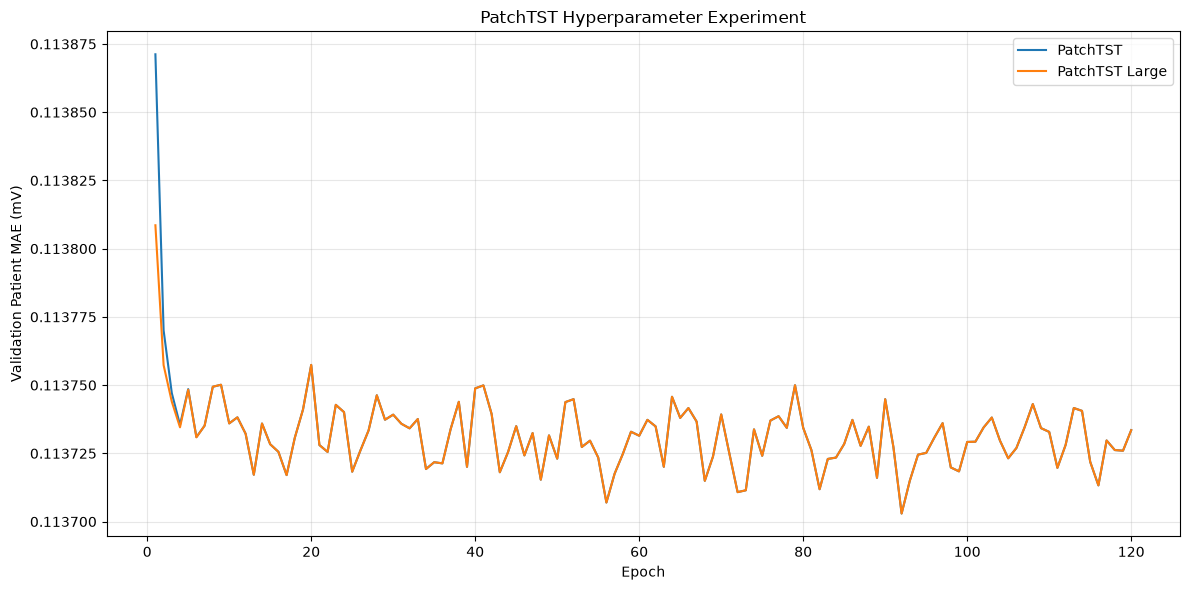

In [43]:
base = pd.read_csv(
    "../results/primary_7s3s_v3/full/checkpoints/"
    "patchtst_P0_F0_full_120e/history.csv"
)

large = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/"
    "patchtst_large_P0_F0_full_120e/history.csv"
)

plt.figure(figsize=(12,6))

plt.plot(
    base["epoch"],
    base["val_patient_macro_mae_mV"],
    label="PatchTST"
)

plt.plot(
    large["epoch"],
    large["val_patient_macro_mae_mV"],
    label="PatchTST Large"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Patient MAE (mV)")

plt.title(
    "PatchTST Hyperparameter Experiment"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "patchtst_hyperparameter_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# PatchTST Hyperparameter Study (Per Lead)

In [53]:
LEAD_NAMES = [
    "I", "II", "III",
    "aVR", "aVL", "aVF",
    "V1", "V2", "V3",
    "V4", "V5", "V6"
]

patch16_leads = pd.read_csv(
    "patch16_leads.csv"
)

patchlarge_leads = pd.read_csv(
    "patchlarge_leads.csv"
)

tft_large_p0_leads = pd.read_csv(
    "tft_large_p0_leads.csv"
)


tft_large_p1_leads = pd.read_csv(
    "tft_large_p1_leads.csv"
)

tft_p0_leads = pd.read_csv(
    "tft_p0_leads.csv"
)

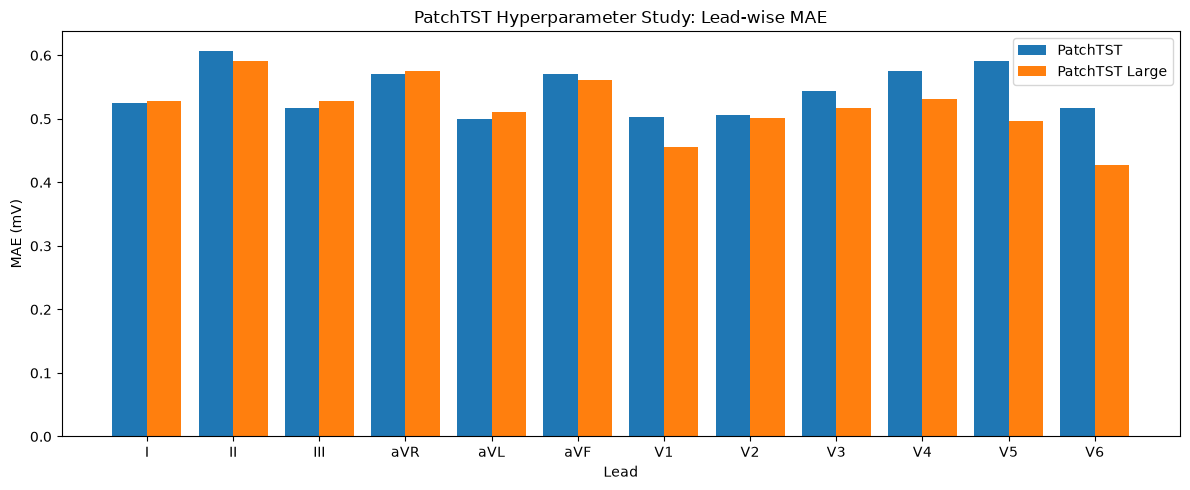

In [49]:
import numpy as np
import matplotlib.pyplot as plt


plt.figure(figsize=(12,5))

plt.bar(
    np.arange(12)-0.2,
    patch16_leads["MAE"],
    width=0.4,
    label="PatchTST"
)

plt.bar(
    np.arange(12)+0.2,
    patchlarge_leads["MAE"],
    width=0.4,
    label="PatchTST Large"
)

plt.xticks(
    np.arange(12),
    LEAD_NAMES
)

plt.ylabel("MAE (mV)")
plt.xlabel("Lead")

plt.title(
    "PatchTST Hyperparameter Study: Lead-wise MAE"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "patchtst_hyperparameter_leads.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# TFT Medium vs TFT Large (Per Lead)

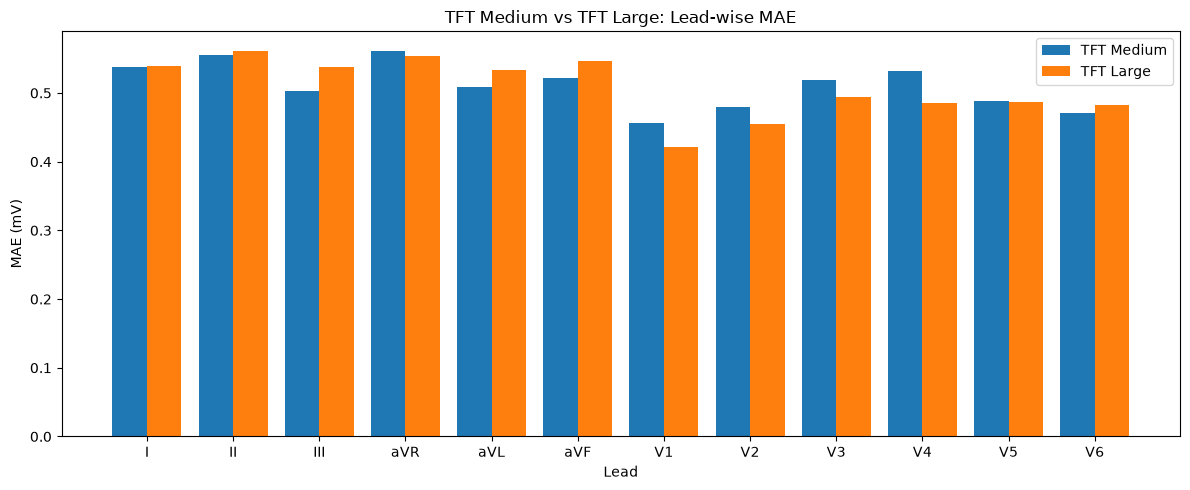

In [55]:
plt.figure(figsize=(12,5))

plt.bar(
    np.arange(12)-0.2,
    tft_p0_leads["MAE"],
    width=0.4,
    label="TFT Medium"
)

plt.bar(
    np.arange(12)+0.2,
    tft_large_p0_leads["MAE"],
    width=0.4,
    label="TFT Large"
)

plt.xticks(
    np.arange(12),
    LEAD_NAMES
)

plt.ylabel("MAE (mV)")
plt.xlabel("Lead")

plt.title(
    "TFT Medium vs TFT Large: Lead-wise MAE"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "tft_medium_vs_large_leads.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# TFT Large P0 vs P1 (Per Lead)

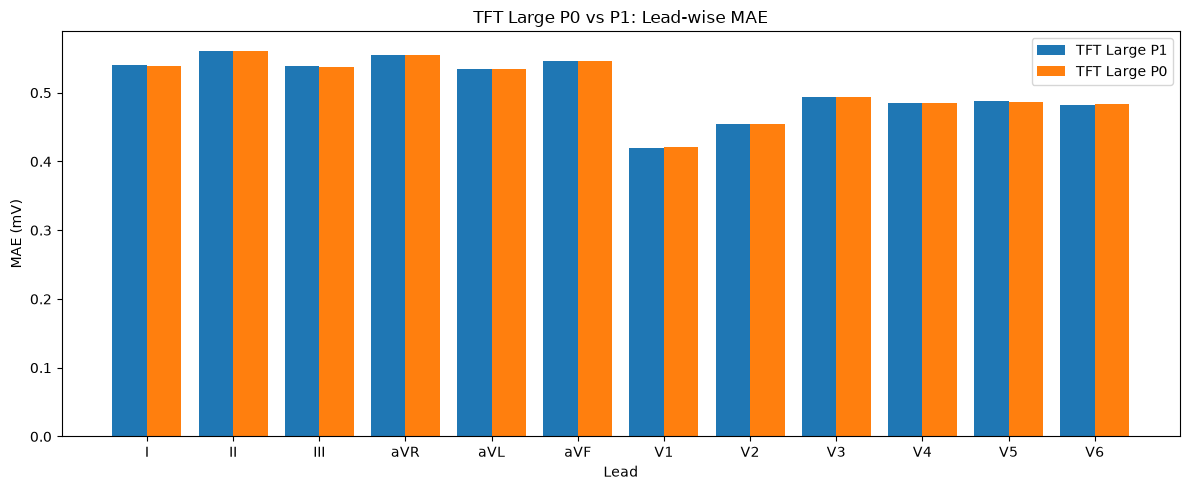

In [62]:
plt.figure(figsize=(12,5))

plt.bar(
    np.arange(12)-0.2,
    tft_large_p1_leads["MAE"],
    width=0.4,
    label="TFT Large P1"
)

plt.bar(
    np.arange(12)+0.2,
    tft_large_p0_leads["MAE"],
    width=0.4,
    label="TFT Large P0"
)

plt.xticks(
    np.arange(12),
    LEAD_NAMES
)

plt.ylabel("MAE (mV)")
plt.xlabel("Lead")

plt.title(
    "TFT Large P0 vs P1: Lead-wise MAE"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "tft_arge_p0_vs_p1_leads.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Lead-wise Heatmap

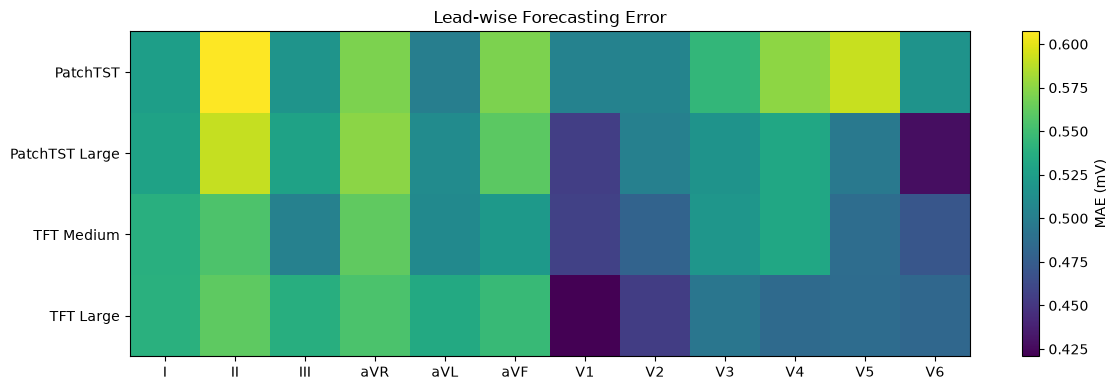

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

heatmap = pd.DataFrame(
    [
        patch16_leads["MAE"].values,
        patchlarge_leads["MAE"].values,
        tft_p0_leads["MAE"].values,
        tft_large_p0_leads["MAE"].values,
    ],
    index=[
        "PatchTST",
        "PatchTST Large",
        "TFT Medium",
        "TFT Large",
    ],
    columns=LEAD_NAMES
)

plt.figure(figsize=(12,4))

plt.imshow(
    heatmap.values,
    aspect="auto"
)

plt.xticks(
    np.arange(len(LEAD_NAMES)),
    LEAD_NAMES
)

plt.yticks(
    np.arange(len(heatmap.index)),
    heatmap.index
)

plt.colorbar(
    label="MAE (mV)"
)

plt.title(
    "Lead-wise Forecasting Error"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "lead_heatmap_extended.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

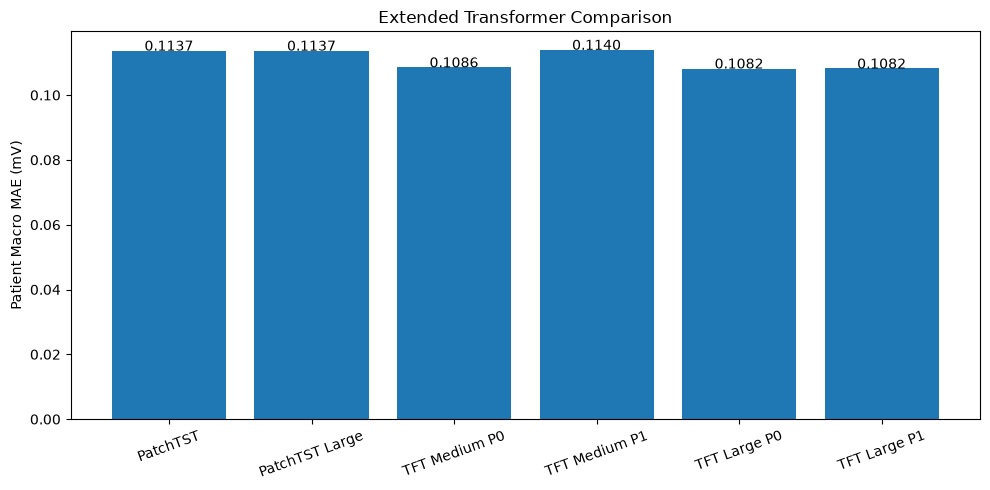

In [69]:
import matplotlib.pyplot as plt

models = [
    "PatchTST",
    "PatchTST Large",
    "TFT Medium P0",
    "TFT Medium P1",
    "TFT Large P0",
    "TFT Large P1",
]

mae = [
    0.113702951232371,
    0.113702951232371,
    0.1085561602102407,
    0.1139630000000000,
    0.1081845357796798,
    0.1081940000000000,
]

plt.figure(figsize=(10,5))

bars = plt.bar(
    models,
    mae
)

for b in bars:
    plt.text(
        b.get_x() + b.get_width()/2,
        b.get_height(),
        f"{b.get_height():.4f}",
        ha="center"
    )

plt.ylabel("Patient Macro MAE (mV)")
plt.title("Extended Transformer Comparison")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" /
    "extended_transformer_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()